# 3. Clustering and road hotspots
We use geographic coordinates to group collision locations. A sample is used for silhouette scoring and hierarchical clustering (dendrogram) to evaluate cluster separation, followed by regional K-Means partitioning.

Chosen regional k: 4 ; silhouette: 0.562


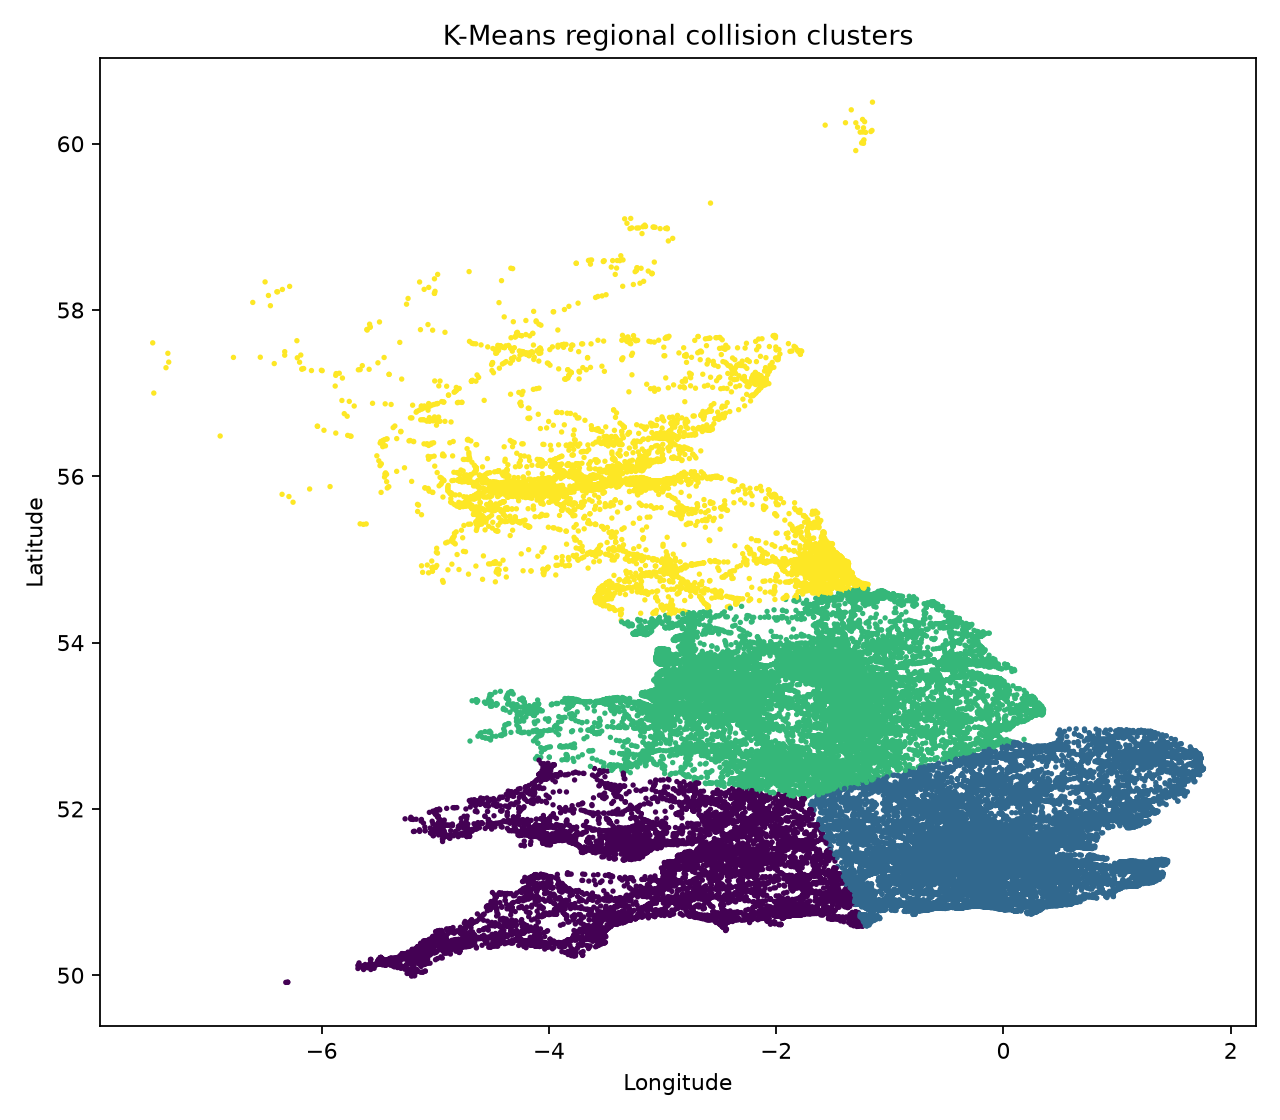

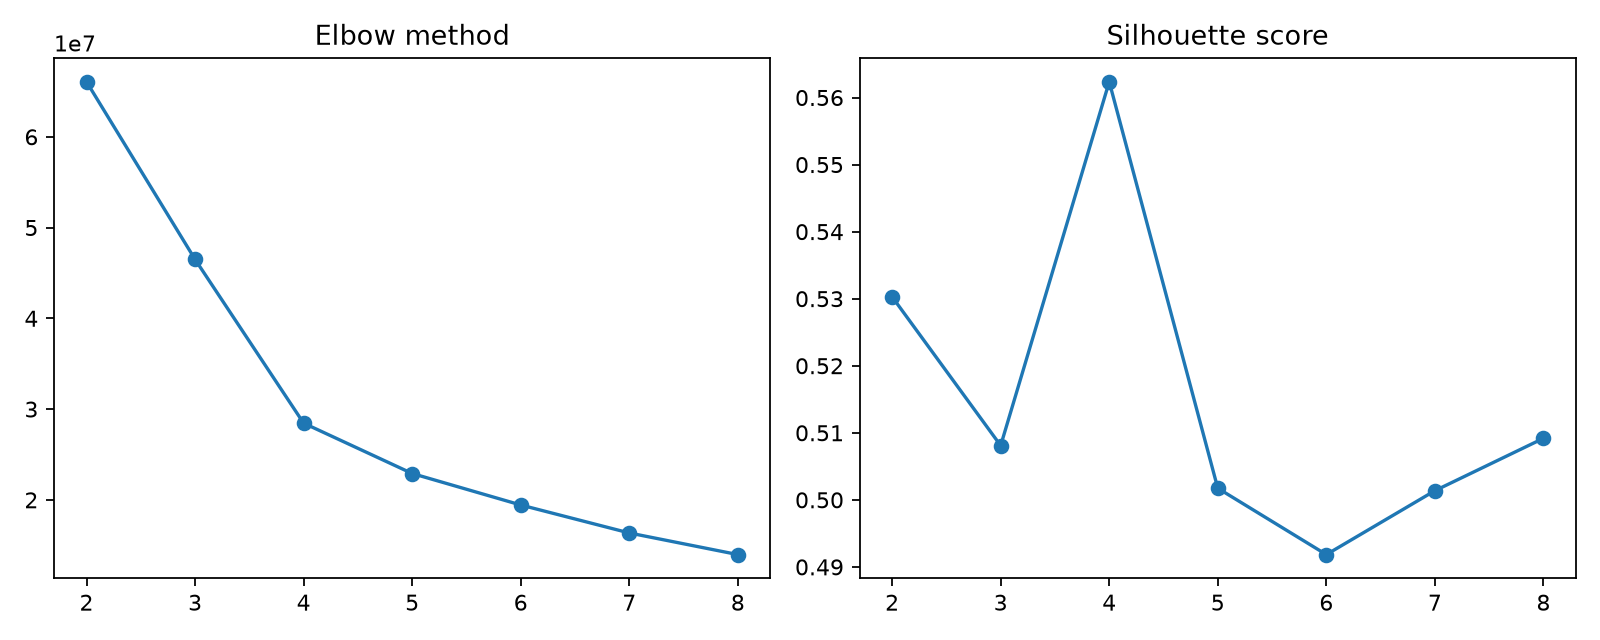

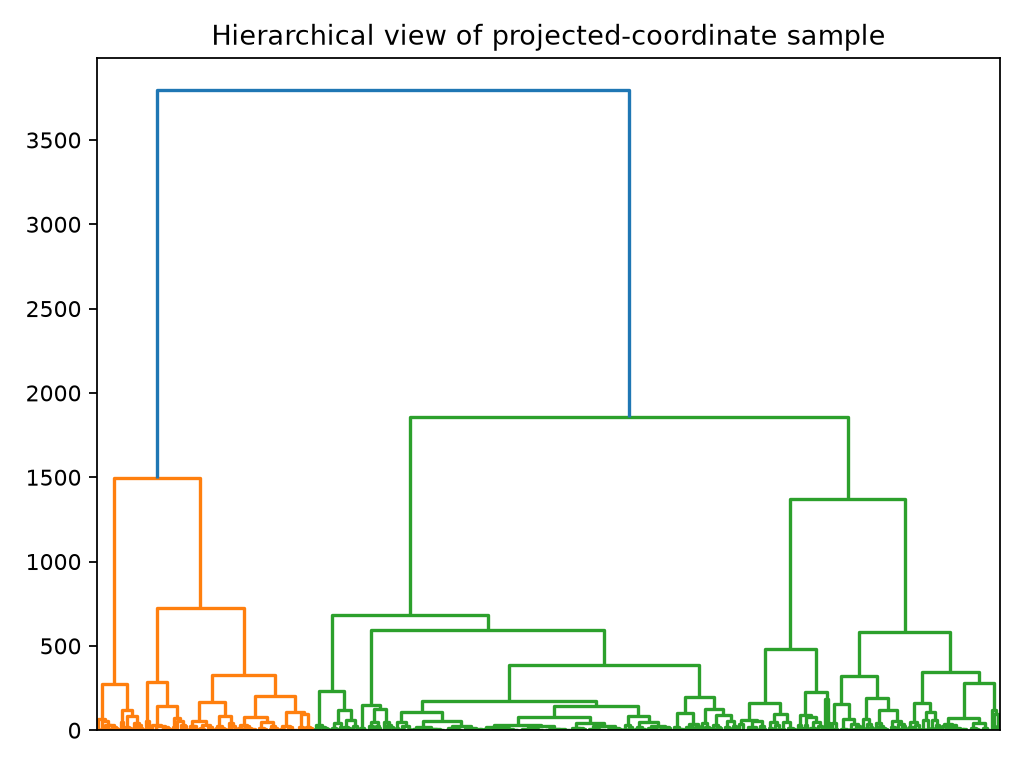

In [2]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import folium
from folium.plugins import HeatMap

ROOT = Path.cwd().resolve()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
df = pd.read_csv(ROOT / 'data/processed/cleaned_accidents.csv')
coords = df[['latitude', 'longitude']].dropna()
lat0 = np.deg2rad(coords.latitude.mean())
projected = pd.DataFrame({
    'x_km': (coords.longitude - coords.longitude.mean()) * 111.32 * np.cos(lat0),
    'y_km': (coords.latitude - coords.latitude.mean()) * 110.57
}, index=coords.index)
sample = projected.sample(min(5000, len(projected)), random_state=42)
ks = range(2, 9); inertias = []; silhouettes = []
for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(sample)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(sample, model.labels_))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertias, 'o-'); ax[0].set_title('Elbow method')
ax[1].plot(ks, silhouettes, 'o-'); ax[1].set_title('Silhouette score')
plt.tight_layout(); plt.savefig(ROOT / 'outputs/figures/clustering_choice.png', dpi=160); plt.close()
k = int(list(ks)[int(np.argmax(silhouettes))])
model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(projected)
df.loc[coords.index, 'cluster'] = model.labels_
link = linkage(sample.sample(min(400, len(sample)), random_state=42), method='ward')
dendrogram(link, no_labels=True); plt.title('Hierarchical view of projected-coordinate sample')
plt.tight_layout(); plt.savefig(ROOT / 'outputs/figures/dendrogram.png', dpi=160); plt.close()

df['serious_fatal'] = df.severity.isin(['Serious', 'Fatal']).astype(int)
regional = df.groupby('cluster').agg(
    accidents=('collision_index', 'count'),
    severe_share=('serious_fatal', 'mean'),
    avg_casualties=('casualty_count', 'mean'),
    latitude=('latitude', 'mean'),
    longitude=('longitude', 'mean')
).reset_index()
for column in ['accidents', 'severe_share', 'avg_casualties']:
    regional[column + '_scaled'] = (regional[column] - regional[column].min()) / (regional[column].max() - regional[column].min() + 1e-9)
regional['risk_score'] = 100 * (regional['accidents_scaled'] + regional['severe_share_scaled'] + regional['avg_casualties_scaled']) / 3
regional = regional.sort_values('risk_score', ascending=False)
regional.to_csv(ROOT / 'outputs/tables/hotspots.csv', index=False)

center = [df.latitude.mean(), df.longitude.mean()]
mp = folium.Map(center, zoom_start=6, tiles='OpenStreetMap')
for _, row in regional.iterrows():
    folium.CircleMarker([row.latitude, row.longitude], radius=5, color='#b54141' if row.risk_score > 60 else '#168c8c', fill=True,
                        popup=f'Region {int(row.cluster)}: composite score {row.risk_score:.1f}, {int(row.accidents)} sampled collisions').add_to(mp)
HeatMap(df[['latitude', 'longitude']].dropna().sample(min(30000, len(df)), random_state=42).values.tolist(), radius=7, name='Collision density').add_to(mp)
folium.LayerControl().add_to(mp)
(ROOT / 'outputs/maps').mkdir(parents=True, exist_ok=True); mp.save(ROOT / 'outputs/maps/hotspots.html')
plt.figure(figsize=(8, 7)); plt.scatter(df.longitude, df.latitude, c=df.cluster, s=2, cmap='viridis')
plt.xlabel('Longitude'); plt.ylabel('Latitude'); plt.title('K-Means regional collision clusters')
plt.tight_layout(); plt.savefig(ROOT / 'outputs/figures/cluster_map.png', dpi=160); plt.close()
print('Chosen regional k:', k, '; silhouette:', round(max(silhouettes), 3))
